In [28]:
import numpy as np
import matplotlib.pyplot as plt
from dspeed.processors import inject_gumbel
from lgdo.types import ArrayOfEqualSizedArrays, WaveformTable
from scipy.integrate import simpson
from matplotlib import colormaps

In [10]:
# --- Waveform generator ---
def wf_generator(num_wfs=1000, amplitude=1000, width=1, t0_start=11, jitter=1, wf_len=32, signal_to_noise=10000, period=5):
    mean = 0
    std = amplitude / signal_to_noise
    empty_wfs = np.random.normal(mean, std, size=(num_wfs, wf_len))
    wfs = np.zeros_like(empty_wfs)
    t0s = np.random.uniform(t0_start, t0_start + jitter, num_wfs)

    for i in range(num_wfs):
        inject_gumbel(empty_wfs[i, :], amplitude, t0s[i], width, wfs[i, :]) 
    
    wf_tab = WaveformTable(values=wfs, dt=period, dt_units="ns", t0=0, t0_units="ns")
    return wf_tab, t0s

In [11]:
def analyze_waveform_pair(wf1, wf2):
    """
    Analyze the difference between two waveforms.

    Parameters:
    - wf1, wf2: 1D numpy arrays of waveform data
    - dt: time step between samples

    Returns:
    - sign (int): +1 if pre-integral is positive, -1 if negative
    - total_magnitude (float): sum of absolute values of integrals
    """
    # Find sign of crossing
    diff = wf1 - wf2
    sign = 1 if np.argmax(diff)<= np.argmin(diff) else -1
    
    # Find the size of the difference between the wfs
    diffsq = diff**2
    magnitude = simpson(diffsq)

    return sign, magnitude

In [12]:
def compute_comparison_matrix(wf_tab):
    """
    Create a matrix where each entry (i, j) is:
    sign * magnitude. 
    
    Diagonal entries are 0.

    Parameters:
    - wf_tab: WaveformTable

    Returns:
    - matrix: 2D numpy array of shape (num_waveforms, num_waveforms)
    """
    wfs = wf_tab.values.nda
    dt = wf_tab.dt[0]
    num_wfs = len(wfs)
    matrix = np.zeros((num_wfs, num_wfs))

    for i in range(num_wfs):
        for j in range(num_wfs):
            if i == j:
                continue  # Leave diagonal as 0
            try:
                sign, magnitude = analyze_waveform_pair(wfs[i], wfs[j])
                matrix[i, j] = sign * magnitude
            except ValueError:
                matrix[i, j] = 0  # In case there's no zero-crossing, assign 0 or NaN if preferred

    return matrix

In [13]:
def reorder_waveforms_by_similarity(wf_tab):
    """
    Reorders waveforms based on similarity scores from the comparison matrix row sums.

    Returns:
    - reordered_wf_tab: WaveformTable with reordered waveforms
    - reordered_matrix: Comparison matrix reordered accordingly
    - sorted_row_sums: 1D array of sorted row sums
    """
    # Step 1: Compute the comparison matrix
    matrix = compute_comparison_matrix(wf_tab)

    # Step 2: Compute row sums
    row_sums = np.sum(matrix, axis=1)

    # Step 3: Get sorted indices (descending)
    sorted_indices = np.argsort(row_sums)[::-1]

    # Step 4: Reorder the waveforms and matrix
    reordered_wfs = wf_tab.values.nda[sorted_indices]
    reordered_matrix = matrix[sorted_indices][:, sorted_indices]
    sorted_row_sums = row_sums[sorted_indices]

    # Step 5: Create new WaveformTable with reordered data
    reordered_wf_tab = WaveformTable(
        values=reordered_wfs,
        dt=wf_tab.dt[0],
        dt_units="ns",
        t0=wf_tab.t0[0],
        t0_units="ns"
    )

    return reordered_wf_tab, reordered_matrix, sorted_row_sums

In [29]:
def plot_waveforms_rainbow(wf_tab):
    """
    Plot all waveforms in the WaveformTable using a rainbow gradient for color. If waveforms are ordered this will produce a rainbow gradient. 

    Parameters:
    - wf_tab: WaveformTable
    """
    wfs = wf_tab.values.nda
    dt = wf_tab.dt[0]
    t = np.linspace(0, len(wfs[0]) * dt, len(wfs[0]))
    num_wfs = len(wfs)

    # Get rainbow colormap
    cmap = colormaps['rainbow']
    plt.figure(figsize=(12, 6))

    for i, wf in enumerate(wfs):
        color = cmap(i / num_wfs)
        plt.plot(t, wf, '.', color=color, linewidth=1)

    # plt.title("RWaveforms", fontsize=14)
    plt.xlabel("Time (ns)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [30]:
def upsampled_template_waveform(
    wfs_in: WaveformTable, upsample_factor: int = 5
) -> WaveformTable:
    """
    Builds an upsampled template waveform by:
    - Splitting already-sorted waveforms into groups
    - Shifting each group backward to align in time (based on group index)
    - Averaging each group
    - Interleaving group averages to simulate upsampling

    Parameters
    ----------
    wfs_in : WaveformTable
        The sorted waveforms (earliest to latest).
    upsample_factor : int
        The number of groups and desired upsampling factor.

    Returns
    -------
    wf_template : WaveformTable
        The upsampled, aligned template waveform.
    """

    if not isinstance(upsample_factor, int) or upsample_factor < 1:
        raise ValueError("Upsample factor must be a positive integer")

    sorted_wfs = wfs_in.values.nda
    dt = wfs_in.dt.nda[0]
    wf_len = sorted_wfs.shape[1]

    # Initialize with zeros
    wf_extended = np.zeros(wf_len * upsample_factor)
    counts = np.zeros(wf_len * upsample_factor)

    # Split waveforms into `upsample_factor` groups
    groups = np.array_split(sorted_wfs, upsample_factor)
    x = np.arange(wf_len)

    # plt.figure(figsize=(12, 6))
    for n, group in enumerate(groups):
        avg = group.mean(axis=0)
        #plt.plot(x, avg,'-.', label=f"Group {n}")
        # plt.plot(x, avg,'-.', label=f"Group {n}")
        for i in range(wf_len):
            wf_extended[upsample_factor*i-n] = avg[i]
    # plt.legend()

    final_waveform = wf_extended

    return WaveformTable(
        values=ArrayOfEqualSizedArrays(nda=final_waveform),
        dt=dt / upsample_factor,
        t0=0,
        t0_units=wfs_in.t0_units,
    )

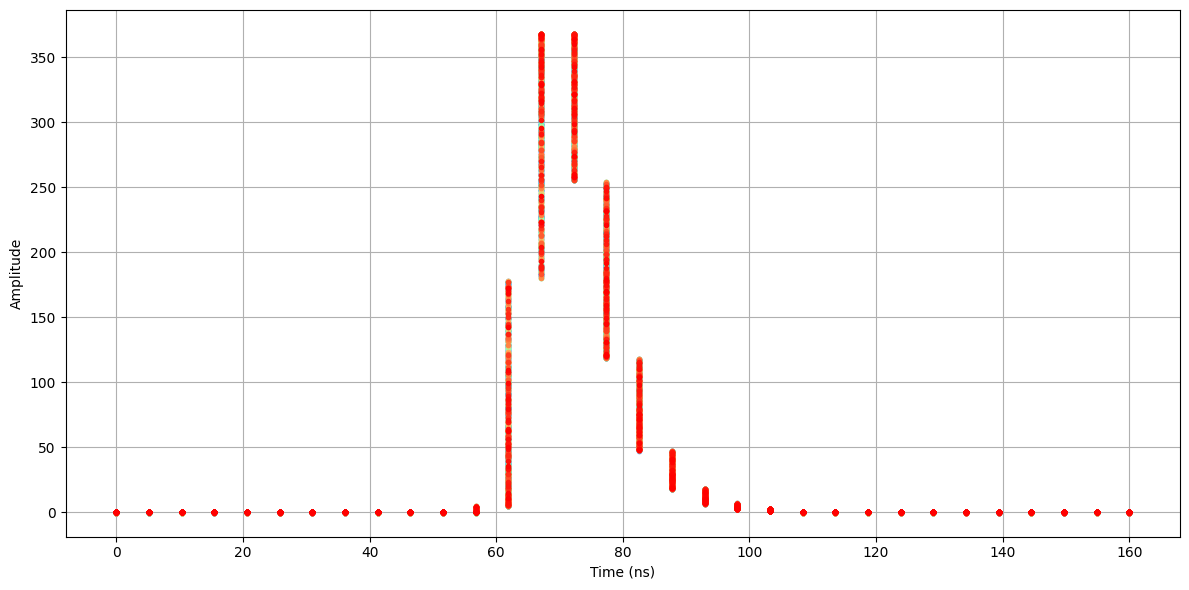

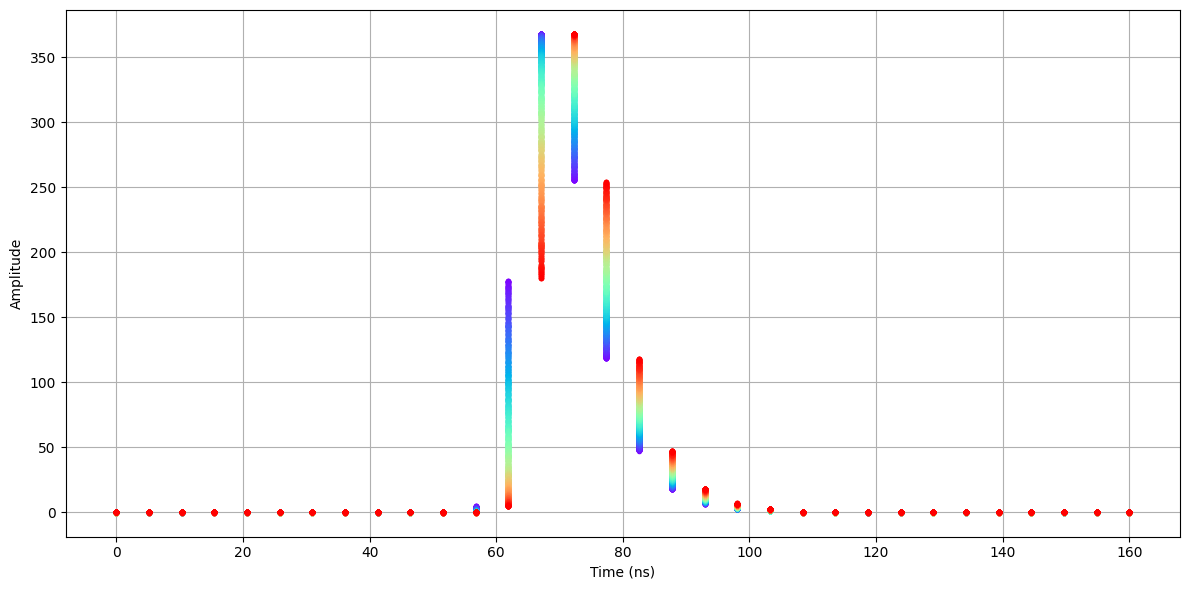

In [31]:
#Generate and reorder waveforms
wf_tab, t0s = wf_generator()
reordered_wf_tab, reordered_matrix, sorted_row_sums = reorder_waveforms_by_similarity(wf_tab)

# Plot them in rainbow color before reordering
plot_waveforms_rainbow(wf_tab)

# Plot with rainbow coloring
plot_waveforms_rainbow(reordered_wf_tab)

[ 0.00057703 -0.00708852 -0.01496014 ...  0.00135793  0.01048795
 -0.00837843]


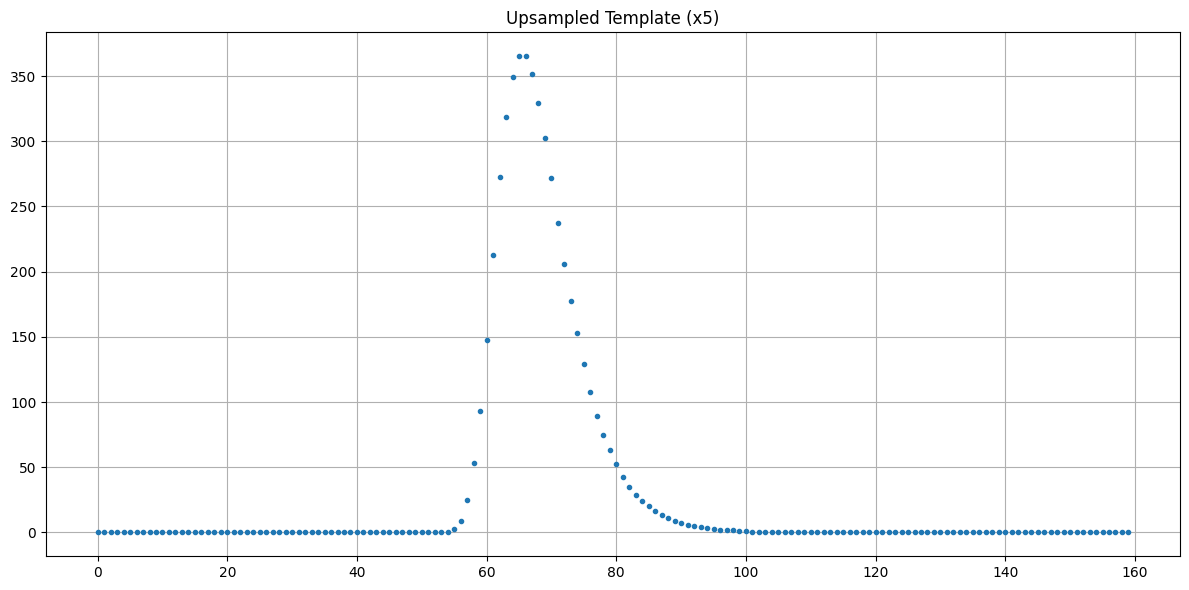

In [32]:
# --- Parameters ---
upsample_factor = 5  # You can change this to any desired factor

# --- Build upsampled waveform template ---
template_wf_table = upsampled_template_waveform(
    wfs_in=reordered_wf_tab,  # <- Replace with your actual variable name if different
    upsample_factor=upsample_factor
)

# --- Extract waveform and time axis for plotting ---
template_wf = template_wf_table.values.nda
print(template_wf)
# dt = template_wf_table.dt.nda[0]
# time_axis = np.arange(len(template_wf)) * dt


plt.figure(figsize=(12, 6))
plt.plot(template_wf,'.')
plt.title(f"Upsampled Template (x{upsample_factor})")
# plt.xlabel("Time")
# plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()